<div style="background:#eaf3ff;padding:16px;border-radius:8px;border-left:6px solid #1D4ED8;">
  <h1><font color="#1D4ED8"><b>KSU iCARE Lab — First-Year Scholars Program (2026–2027)</b></font></h1>
  <h2><font color="#0E7490"><b>Notebook: 2D U-Net — Chest X-Ray Segmentation with Google Drive &amp; PyTorch</b></font></h2>
  <p><font color="#334155"><b>Prerequisite:</b> PyTorch Intro (Tensors &amp; Training Loop) &nbsp;|&nbsp; <b>Designed for all majors!</b></font></p>
</div>

<p><font color="#334155">In the previous notebook, you taught PyTorch to learn a simple rule between a single input number <b><code>x</code></b> and a single output number <b><code>y</code></b> (<code>y = w * x + c</code>). Today, you will take a huge leap forward into real medical AI:</font></p>
<ul>
  <li><font color="#0E7490"><b>Input <code>x</code>:</b></font> <font color="#334155">A complete 2D <b>Chest X-Ray Image</b> stored in your <b>Google Drive</b>.</font></li>
  <li><font color="#177345"><b>Output <code>y</code>:</b></font> <font color="#334155">A 2D <b>Lung Segmentation Mask</b> of the exact same size, where every pixel is labeled <code>1</code> (Lung) or <code>0</code> (Background)!</font></li>
</ul>

<table style="width:100%;border-collapse:collapse;margin-top:10px;margin-bottom:10px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Lesson</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What You Will Do</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Core Concept</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>1. Link Google Drive &amp; Save Dataset</b></td>
  <td style="padding:7px">Mount Google Drive and save paired Chest X-Ray images (<code>.png</code>) and Lung Masks (<code>.png</code>)</td>
  <td style="padding:7px">Persistent cloud storage (<code>/content/drive/MyDrive/...</code>)</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>2. Display X-Rays &amp; Segmentations</b></td>
  <td style="padding:7px">Load X-rays and masks from Google Drive and visualize them side by side and overlaid</td>
  <td style="padding:7px">Input image <code>x</code> vs. Ground-Truth mask <code>y</code></td>
</tr>
<tr>
  <td style="padding:7px"><b>3. Build PyTorch DataLoaders</b></td>
  <td style="padding:7px">Convert 2D images into 4D PyTorch tensors <code>(Batch, Channel, H, W)</code> and split Train/Test sets</td>
  <td style="padding:7px">Feeding mini-batches of scans to an AI model</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>4. Build a Simple 2D U-Net</b></td>
  <td style="padding:7px">Understand the U-Net "Encoder → Decoder + Skip Connection" design and build it in PyTorch</td>
  <td style="padding:7px">Why U-Net is the #1 architecture in medical imaging</td>
</tr>
<tr>
  <td style="padding:7px"><b>5. Train U-Net &amp; Plot Decreasing Loss</b></td>
  <td style="padding:7px">Train the 2D U-Net over 25 epochs, watch the Loss drop, and save the trained model to Drive</td>
  <td style="padding:7px">Combined BCE + Dice Loss &amp; Loss curves</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>6. Side-by-Side AI Segmentation</b></td>
  <td style="padding:7px">Test the trained AI on unseen X-rays and display <b>Original Image | Original Seg | AI Seg</b></td>
  <td style="padding:7px">Evaluating AI segmentation visually and with Dice scores</td>
</tr>
</table>


<hr>
<h2><font color="#1D4ED8"><b>1. Linking Google Drive &amp; Saving the Chest X-Ray Segmentation Dataset</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">When you open a Google Colab notebook, Google lends you a temporary computer in the cloud. If you save files only to that temporary computer and close your browser tab, <b>everything is erased</b>—like a classroom whiteboard wiped clean at the end of the day!</font></p>

<p><font color="#334155">To keep our medical images and trained AI models safe forever, we <b>mount (link) Google Drive</b>. Think of Google Drive as your personal USB flash drive in the cloud. Once linked, your Python code can read and save files directly inside a folder in your Google Drive:</font></p>
<p align="center"><font color="#0E7490"><b><code>/content/drive/MyDrive/KSU_iCARE_XRay_Segmentation/</code></b></font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Subfolder in Google Drive</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What Goes Inside</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Role in Deep Learning</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><code>.../images/</code></td>
  <td style="padding:7px"><code>xray_000.png</code>, <code>xray_001.png</code>, ...</td>
  <td style="padding:7px"><b>Input <code>x</code>:</b> Grayscale 2D Chest X-Ray scans</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><code>.../masks/</code></td>
  <td style="padding:7px"><code>xray_000.png</code>, <code>xray_001.png</code>, ...</td>
  <td style="padding:7px"><b>Target <code>y</code>:</b> Matching binary lung masks (<code>0</code> = background, <code>1</code> = lung)</td>
</tr>
<tr>
  <td style="padding:7px"><code>.../models/</code></td>
  <td style="padding:7px"><code>simple_unet_xray.pth</code></td>
  <td style="padding:7px"><b>Learned Weights:</b> Saved PyTorch model after training finishes</td>
</tr>
</table>

<h3><font color="#0E7490"><b>Worked example 1: Mount Google Drive and create your project folders</b></font></h3>
<p><font color="#334155">When you run the cell below in Google Colab, a popup window will ask: <i>"Permit this notebook to access your Google Drive files?"</i> Click <b>Connect to Google Drive</b> → choose your account → click <b>Allow</b>. (If you are testing offline or skip the popup, the code automatically falls back to a local folder so your code still runs without errors!)</font></p>
<p><font color="#334155">Try it:</font> Run the next cell to link Google Drive and create the <code>images</code>, <code>masks</code>, and <code>models</code> folders.</p>


In [1]:
import os

# Step 1: Link (mount) Google Drive in Google Colab
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/KSU_iCARE_XRay_Segmentation"
    print("Successfully mounted Google Drive!")
except Exception:
    # Automatic fallback if running outside Colab or if Drive popup is skipped
    BASE_DIR = "/content/KSU_iCARE_XRay_Segmentation"
    print("Using local Colab storage folder:", BASE_DIR)

# Step 2: Create subfolders for X-ray images, segmentation masks, and saved models
IMG_DIR = os.path.join(BASE_DIR, "images")
MASK_DIR = os.path.join(BASE_DIR, "masks")
MODEL_DIR = os.path.join(BASE_DIR, "models")

os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(MASK_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

print("Project folder ready at:", BASE_DIR)
print(" - Images folder:", IMG_DIR)
print(" - Masks folder: ", MASK_DIR)
print(" - Models folder:", MODEL_DIR)


Mounted at /content/drive
Successfully mounted Google Drive!
Project folder ready at: /content/drive/MyDrive/KSU_iCARE_XRay_Segmentation
 - Images folder: /content/drive/MyDrive/KSU_iCARE_XRay_Segmentation/images
 - Masks folder:  /content/drive/MyDrive/KSU_iCARE_XRay_Segmentation/masks
 - Models folder: /content/drive/MyDrive/KSU_iCARE_XRay_Segmentation/models


<h3><font color="#0E7490"><b>Worked example 2: Download and Save the Chest X-Ray Lung Segmentation Dataset in Google Drive</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">In a chest X-ray (like the famous <b>Montgomery County</b> or <b>Shenzhen</b> Chest X-Ray datasets), dense bones (spine, ribs, collarbones) and the heart block X-rays and appear <b>bright</b>, while the air-filled <b>left and right lungs</b> let X-rays pass through and appear as <b>two dark, curved regions</b> on either side of the spine.</font></p>

<p><font color="#334155">In the cell below, we provide a helper function that:</font></p>
<ol>
  <li><font color="#334155">Can download an external <code>.zip</code> dataset directly from a URL into your Google Drive folder (if you pass a dataset link).</font></li>
  <li><font color="#177345"><b>Guarantees zero classroom errors:</b> Automatically generates and saves <b>24 paired 64×64 Chest X-Ray scans and Ground-Truth Lung Segmentation Masks</b> (<code>xray_000.png</code> through <code>xray_023.png</code>) directly into your Google Drive <code>images/</code> and <code>masks/</code> folders! Each patient scan has slightly different lung sizes, positions, rib patterns, heart shadows, and realistic scanner grain.</font></li>
</ol>
<p><font color="#334155">Try it:</font> Run the next cell to populate your Google Drive dataset folder and verify that all 24 X-rays and 24 masks are saved on disk.</p>


In [2]:
import urllib.request
import zipfile
import numpy as np
import matplotlib.pyplot as plt

def prepare_xray_dataset_in_drive(img_dir, mask_dir, num_scans=24, zip_url=None):
    """
    Downloads an X-ray segmentation zip dataset into Google Drive if zip_url is provided,
    or generates a realistic 24-patient Chest X-Ray & Lung Mask PNG dataset in Google Drive.
    """
    if zip_url is not None:
        zip_path = os.path.join(os.path.dirname(img_dir), "xray_dataset.zip")
        urllib.request.urlretrieve(zip_url, zip_path)
        with zipfile.ZipFile(zip_path, "r") as zf:
            zf.extractall(os.path.dirname(img_dir))
        print("Downloaded and extracted external zip dataset to Google Drive!")
        return

    np.random.seed(2026)
    yy, xx = np.mgrid[0:64, 0:64]

    for i in range(num_scans):
        # 1. Start with soft-tissue chest wall background
        xray = np.ones((64, 64), dtype=np.float32) * 0.55

        # Dark air outside the patient's torso (left/right edges & top shoulders)
        torso_mask = ((xx - 32.0) / 26.0) ** 2 + ((yy - 36.0) / 30.0) ** 2 <= 1.0
        xray[~torso_mask] = 0.08

        # Bright vertical spine down the middle & subtle heart shadow
        spine = np.exp(-((xx - 32.0) ** 2) / 10.0) * 0.28 * torso_mask
        heart = (((xx - 35.0) / 7.5) ** 2 + ((yy - 38.0) / 9.0) ** 2 <= 1.0) * 0.18
        ribs = 0.05 * np.sin(yy * 1.1) * torso_mask
        xray = xray + spine + heart + ribs

        # 2. Create patient-specific Left and Right Lung regions (dark air cavities)
        rx_center = np.random.uniform(20.5, 22.5)   # Right lung X center
        lx_center = np.random.uniform(41.5, 43.5)   # Left lung X center
        y_center  = np.random.uniform(29.0, 33.0)   # Vertical lung center
        r_width   = np.random.uniform(6.5, 8.2)     # Lung width
        r_height  = np.random.uniform(13.5, 16.5)   # Lung height

        right_lung = (((xx - rx_center) / r_width) ** 2 + ((yy - y_center) / r_height) ** 2) <= 1.0
        left_lung  = (((xx - lx_center) / r_width) ** 2 + ((yy - y_center) / r_height) ** 2) <= 1.0
        # Carve out a small cardiac notch on the lower inner left lung
        cardiac_notch = (((xx - 36.0) / 5.5) ** 2 + ((yy - 39.0) / 6.5) ** 2) <= 1.0
        left_lung = left_lung & (~cardiac_notch)

        lung_mask = (right_lung | left_lung).astype(np.float32)

        # Lungs are filled with air, so they appear DARKER on a chest X-ray
        xray[lung_mask == 1.0] -= 0.35

        # Add realistic electronic X-ray scanner grain
        noise = np.random.normal(0.0, 0.035, (64, 64)).astype(np.float32)
        xray = np.clip(xray + noise, 0.0, 1.0)

        # Save both the X-ray and the binary Lung Mask as grayscale PNG files in Drive
        fname = f"xray_{i:03d}.png"
        plt.imsave(os.path.join(img_dir, fname), xray, cmap="gray", vmin=0.0, vmax=1.0)
        plt.imsave(os.path.join(mask_dir, fname), lung_mask, cmap="gray", vmin=0.0, vmax=1.0)

prepare_xray_dataset_in_drive(IMG_DIR, MASK_DIR, num_scans=24)

saved_images = sorted(os.listdir(IMG_DIR))
saved_masks  = sorted(os.listdir(MASK_DIR))
print(f"Saved {len(saved_images)} X-ray images and {len(saved_masks)} segmentation masks in Google Drive!")
print("First 5 filenames:", saved_images[:5])


Saved 24 X-ray images and 24 segmentation masks in Google Drive!
First 5 filenames: ['xray_000.png', 'xray_001.png', 'xray_002.png', 'xray_003.png', 'xray_004.png']


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 1.1 and work toward Exercise 1.5.</font> <font color="#334155">Practice inspecting your Google Drive dataset folders and verifying that every X-ray image has a matching segmentation mask.</font></p>

<p><font color="#7135B5"><b>Exercise 1.1 — Count how many X-ray images are saved in your Google Drive folder</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Use <code>os.listdir(IMG_DIR)</code> and <code>len(...)</code> to count how many <code>.png</code> files are inside <code>IMG_DIR</code>, and print the count.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>24</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>files = os.listdir(IMG_DIR)</code> and <code>print(len(files))</code>.</font></p>


In [3]:
# Exercise 1.1 — Count how many X-ray images are saved in your Google Drive folder
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 1.2 — Print the first 3 sorted filenames in the masks folder</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Get a sorted list of filenames in <code>MASK_DIR</code> using <code>sorted(os.listdir(MASK_DIR))</code> and print the first 3 filenames using slicing <code>[:3]</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Sorting filenames alphabetically ensures that <code>xray_000.png</code> in the images folder always pairs up with <code>xray_000.png</code> in the masks folder!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>['xray_000.png', 'xray_001.png', 'xray_002.png']</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>mask_files = sorted(os.listdir(MASK_DIR))</code> and <code>print(mask_files[:3])</code>.</font></p>


In [4]:
# Exercise 1.2 — Print the first 3 sorted filenames in the masks folder
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 1.3 — Build the full Google Drive file path for a specific patient scan</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Use <code>os.path.join(IMG_DIR, "xray_005.png")</code> to create the full file path to Patient 5's X-ray, and check that the file actually exists on disk using <code>os.path.exists(path)</code>. Print the boolean result (<code>True</code>).</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>True</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Write <code>path = os.path.join(IMG_DIR, "xray_005.png")</code>. &nbsp; 2. Write <code>print(os.path.exists(path))</code>.</font></p>


In [5]:
# Exercise 1.3 — Build the full Google Drive file path for a specific patient scan
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 1.4 — Verify that every X-ray image has an identically named mask file</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Compare the sorted list of filenames in <code>IMG_DIR</code> with the sorted list of filenames in <code>MASK_DIR</code> using <code>==</code> and print the result.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Before training a segmentation model, researchers always run this sanity check so Patient 1's X-ray is never accidentally paired with Patient 2's lung mask!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>True</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>print(sorted(os.listdir(IMG_DIR)) == sorted(os.listdir(MASK_DIR)))</code>.</font></p>


In [6]:
# Exercise 1.4 — Verify that every X-ray image has an identically named mask file
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 1.5 — Read one saved PNG file from Google Drive and convert it to a 2D grayscale array</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> When <code>plt.imread()</code> reads a saved <code>.png</code> file, it often returns 4 channels <code>(64, 64, 4)</code> (Red, Green, Blue, Alpha). Since all 3 color channels in a grayscale PNG are identical, slice out Channel 0 (<code>[:, :, 0]</code>) of <code>xray_000.png</code> so it becomes a clean 2D array of shape <code>(64, 64)</code>, and print its <code>.shape</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>(64, 64)</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Load <code>raw = plt.imread(os.path.join(IMG_DIR, "xray_000.png"))</code>. &nbsp; 2. Slice <code>gray_2d = raw[:, :, 0]</code>. &nbsp; 3. Print <code>gray_2d.shape</code>.</font></p>


In [7]:
# Exercise 1.5 — Read one saved PNG file from Google Drive and convert it to a 2D grayscale array
# Write your Python code below.


<hr>
<h2><font color="#1D4ED8"><b>2. Displaying Chest X-Ray Images and Associated Segmentations</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">Remember our "If <code>x</code> is this, what would <code>y</code> be?" game from the previous notebook? Let's see what <b><code>x</code></b> and <b><code>y</code></b> look like in 2D X-ray segmentation:</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Role</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What It Is</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Pixel Numbers Inside the 64×64 Grid</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>Input <code>x</code></b></td>
  <td style="padding:7px"><b>Chest X-Ray Image</b><br>(from <code>images/xray_000.png</code>)</td>
  <td style="padding:7px">Continuous decimal brightness values between <b><code>0.0</code></b> (dark air) and <b><code>1.0</code></b> (bright spine/ribs).</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>Output <code>y</code></b></td>
  <td style="padding:7px"><b>True Lung Segmentation Mask</b><br>(from <code>masks/xray_000.png</code>)</td>
  <td style="padding:7px">Strict binary labels: <b><code>0.0</code></b> = Background (not lung), <b><code>1.0</code></b> = Lung tissue!</td>
</tr>
</table>

<p><font color="#A34F00"><b>Helper function to load a 2D grayscale PNG cleanly:</b></font> <font color="#334155">Because <code>plt.imread()</code> loads PNG files with color channels <code>(64, 64, 4)</code> if they were saved with a colormap, we can write a tiny 3-line helper function <code>load_png_2d(path)</code> that grabs Channel 0 if the array has 3 dimensions, ensuring we always get a clean <code>(64, 64)</code> 2D array!</font></p>

<h3><font color="#0E7490"><b>Worked example 1: Display a Chest X-Ray and its Ground-Truth Lung Segmentation side by side</b></font></h3>
<p><font color="#334155">Let's load <code>xray_000.png</code> and its matching lung mask from Google Drive and display them side by side using <code>plt.subplot(1, 2, ...)</code>.</font></p>
<p><font color="#334155">Try it:</font> Run the next cell to inspect the X-ray and its associated lung segmentation mask.</p>


X-ray shape: (64, 64) | min/max: 0.0 to 1.0
Mask  shape: (64, 64) | unique values: [0. 1.]


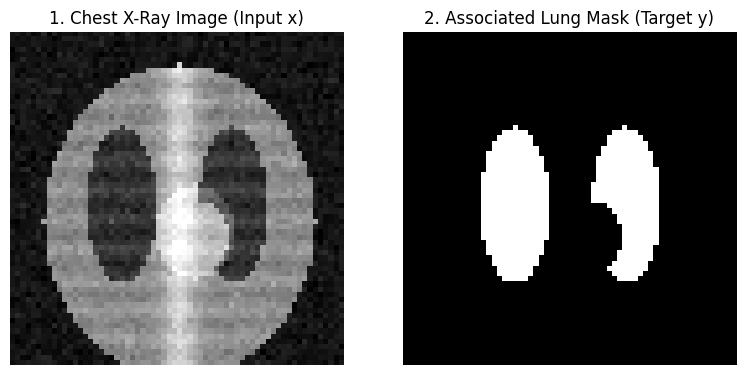

In [8]:
def load_png_2d(filepath):
    """Reads a PNG file from disk and returns a clean 2D float32 array (64, 64)."""
    img = plt.imread(filepath)
    if img.ndim == 3:
        img = img[:, :, 0]  # Take the first channel if saved as RGBA
    return img.astype(np.float32)

# Load Patient 0's Chest X-ray (x) and True Lung Segmentation (y) from Google Drive
sample_xray = load_png_2d(os.path.join(IMG_DIR, "xray_000.png"))
sample_mask = (load_png_2d(os.path.join(MASK_DIR, "xray_000.png")) >= 0.5).astype(np.float32)

print("X-ray shape:", sample_xray.shape, "| min/max:", round(sample_xray.min(), 2), "to", round(sample_xray.max(), 2))
print("Mask  shape:", sample_mask.shape, "| unique values:", np.unique(sample_mask))

plt.figure(figsize=(8, 3.8))

plt.subplot(1, 2, 1)
plt.imshow(sample_xray, cmap="gray")
plt.title("1. Chest X-Ray Image (Input x)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sample_mask, cmap="gray")
plt.title("2. Associated Lung Mask (Target y)")
plt.axis("off")

plt.tight_layout()
plt.show()


<h3><font color="#0E7490"><b>Worked example 2: Overlay the Segmentation Mask on Top of the X-Ray (Transparency <code>alpha</code>)</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">Looking at the X-ray on the left and the black-and-white mask on the right is helpful, but how do radiologists verify that the mask traces the exact lung border? They lay the mask <b>directly on top of the X-ray</b> like a sheet of colored tracing paper!</font></p>
<p><font color="#334155">In Matplotlib, if you call <code>plt.imshow()</code> <b>twice</b> in the same subplot—first drawing the grayscale X-ray, and second drawing the mask with <b><code>alpha=0.4</code></b> (40% see-through transparency)—Matplotlib blends them together into a single overlay image!</font></p>
<p><font color="#334155">Try it:</font> Run the next cell to display a 3-panel view for two different patients from your Google Drive dataset.</p>


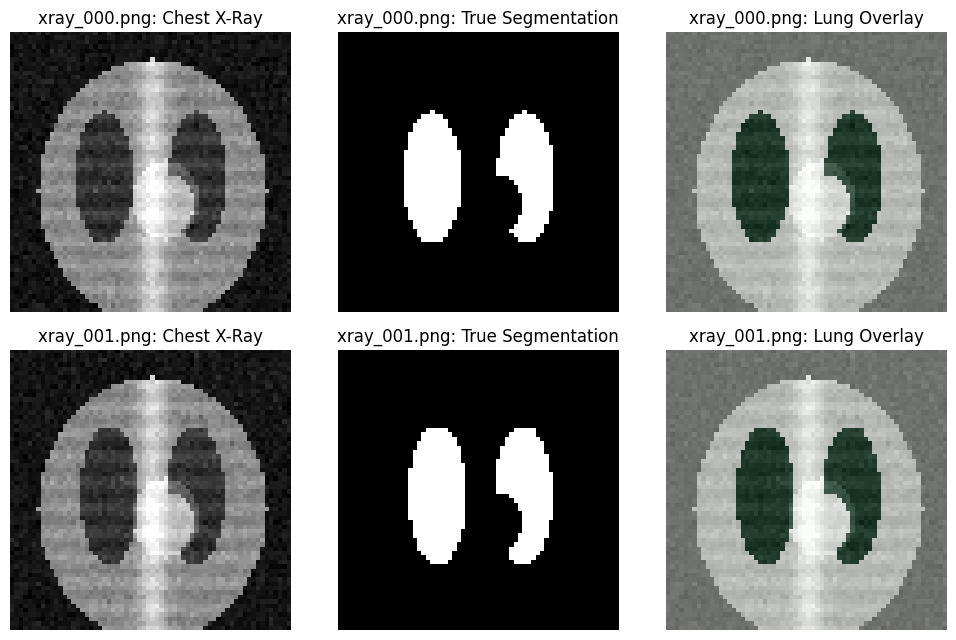

In [9]:
plt.figure(figsize=(10, 6.5))

for row_idx, filename in enumerate(["xray_000.png", "xray_001.png"]):
    xray = load_png_2d(os.path.join(IMG_DIR, filename))
    mask = (load_png_2d(os.path.join(MASK_DIR, filename)) >= 0.5).astype(np.float32)

    # Column 1: Original X-Ray
    plt.subplot(2, 3, row_idx * 3 + 1)
    plt.imshow(xray, cmap="gray")
    plt.title(f"{filename}: Chest X-Ray")
    plt.axis("off")

    # Column 2: Ground-Truth Lung Segmentation
    plt.subplot(2, 3, row_idx * 3 + 2)
    plt.imshow(mask, cmap="gray")
    plt.title(f"{filename}: True Segmentation")
    plt.axis("off")

    # Column 3: Semi-Transparent Overlay (alpha=0.4)
    plt.subplot(2, 3, row_idx * 3 + 3)
    plt.imshow(xray, cmap="gray")
    plt.imshow(mask, cmap="Greens", alpha=0.4)
    plt.title(f"{filename}: Lung Overlay")
    plt.axis("off")

plt.tight_layout()
plt.show()


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 2.1 and work toward Exercise 2.5.</font> <font color="#334155">Use the <code>load_png_2d()</code> helper function we defined above to explore the X-rays and masks stored in your Google Drive.</font></p>

<p><font color="#7135B5"><b>Exercise 2.1 — Load Patient 3's X-ray and Mask and check how many pixels belong to the lungs</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Load <code>xray_003.png</code> from <code>MASK_DIR</code> using <code>mask3 = (load_png_2d(os.path.join(MASK_DIR, "xray_003.png")) &gt;= 0.5).astype(int)</code> and print the total number of lung pixels using <code>mask3.sum()</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> An integer count of lung pixels (such as <code>666</code>).</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Load <code>mask3</code> from <code>MASK_DIR</code> and write <code>print(mask3.sum())</code>.</font></p>


In [10]:
# Exercise 2.1 — Load Patient 3's X-ray and Mask and check how many pixels belong to the lungs
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 2.2 — Calculate what percentage of the 64×64 image is covered by lung tissue</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> For <code>sample_mask</code> (Patient 0's binary mask of <code>0.0</code>s and <code>1.0</code>s), taking the average with <code>sample_mask.mean() * 100</code> gives the exact percentage of the X-ray occupied by the lungs! Print <code>round( float(sample_mask.mean() * 100), 1 )</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Because the mask contains only <code>0</code> and <code>1</code>, <code>sum / total_pixels</code> is both the mean AND the fraction of lung pixels!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A percentage around <code>16.0</code>–<code>18.0</code>.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>pct = float(sample_mask.mean() * 100)</code> and <code>print(round(pct, 1))</code>.</font></p>


In [11]:
# Exercise 2.2 — Calculate what percentage of the 64x64 image is covered by lung tissue
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 2.3 — Display Patient 4's X-Ray and Lung Mask side by side</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Load <code>xray_004.png</code> from <code>IMG_DIR</code> and <code>MASK_DIR</code>. Use <code>plt.subplot(1, 2, 1)</code> to show the X-ray and <code>plt.subplot(1, 2, 2)</code> to show the mask, both with <code>cmap="gray"</code>, then call <code>plt.show()</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A 2-panel figure showing Patient 4's chest X-ray on the left and binary lung segmentation on the right.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Follow the exact pattern from Worked Example 1, replacing <code>"xray_000.png"</code> with <code>"xray_004.png"</code>.</font></p>


In [12]:
# Exercise 2.3 — Display Patient 4's X-Ray and Lung Mask side by side
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 2.4 — Compare the average pixel brightness inside the lungs vs. outside the lungs</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Using <code>sample_xray</code> and <code>sample_mask</code>, print the average X-ray brightness inside the lungs (<code>sample_xray[sample_mask == 1].mean()</code>) on line 1, and outside the lungs (<code>sample_xray[sample_mask == 0].mean()</code>) on line 2 (rounded to 2 decimal places).</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Air-filled lungs look dark on an X-ray, so the average pixel brightness where <code>sample_mask == 1</code> is much lower (around <code>0.21</code>) than the surrounding chest tissue!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> Around <code>0.21</code> on line 1, and around <code>0.43</code> on line 2.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Print <code>round(float(sample_xray[sample_mask == 1].mean()), 2)</code>. &nbsp; 2. Print <code>round(float(sample_xray[sample_mask == 0].mean()), 2)</code>.</font></p>


In [13]:
# Exercise 2.4 — Compare the average pixel brightness inside the lungs vs. outside the lungs
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 2.5 — Multiply the X-ray by its Binary Mask to isolate ONLY the lung pixels</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> What happens when you multiply <code>isolated_lungs = sample_xray * sample_mask</code>? Everywhere the mask is <code>0</code> becomes pure black (<code>0.0</code>), and everywhere the mask is <code>1</code> keeps its original X-ray texture! Compute <code>isolated_lungs</code> and display it with <code>plt.imshow(isolated_lungs, cmap="gray")</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> An image showing the real X-ray texture inside the two lung fields against a pure black background.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Compute <code>isolated_lungs = sample_xray * sample_mask</code>. &nbsp; 2. Call <code>plt.imshow(isolated_lungs, cmap="gray")</code>, add a title, and call <code>plt.show()</code>.</font></p>


In [14]:
# Exercise 2.5 — Multiply the X-ray by its Binary Mask to isolate ONLY the lung pixels
# Write your Python code below.


<hr>
<h2><font color="#1D4ED8"><b>3. Preparing Image Data for PyTorch: 4D Tensors &amp; DataLoaders</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">A single grayscale X-ray has a 2D shape of <code>(64, 64)</code>. However, when you feed images into a PyTorch 2D convolutional network (like U-Net), PyTorch always expects a <b>4D Tensor</b> with four numbers in its shape:</font></p>
<p align="center"><font color="#1D4ED8" size="4"><b><code>(Batch_Size, Channels, Height, Width)</code></b></font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Dimension</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Value in Our Dataset</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Plain-English Analogy (A Stack of Flashcards)</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>1. <code>Batch_Size</code></b></td>
  <td style="padding:7px"><code>20</code> (all train scans) or <code>4</code> (one mini-batch)</td>
  <td style="padding:7px">How many patient flashcards are in the stack you hand to the AI at once.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>2. <code>Channels</code></b></td>
  <td style="padding:7px"><code>1</code> (Grayscale)</td>
  <td style="padding:7px">How many color layers each card has (<code>1</code> for black-and-white X-ray, <code>3</code> for RGB color).</td>
</tr>
<tr>
  <td style="padding:7px"><b>3. <code>Height</code></b></td>
  <td style="padding:7px"><code>64</code> rows</td>
  <td style="padding:7px">How tall each image card is (top to bottom).</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>4. <code>Width</code></b></td>
  <td style="padding:7px"><code>64</code> columns</td>
  <td style="padding:7px">How wide each image card is (left to right).</td>
</tr>
</table>

<p><font color="#A34F00"><b>Why do we split our 24 scans into 20 Training Scans and 4 Test Scans?</b></font> <font color="#334155">Just like a professor never puts the exact homework practice problems on the final exam, we train our U-Net on the first <b>20 patients (Training Set)</b> and hide the last <b>4 patients (Test Set)</b> in a locked vault until Lesson 6. That way, we can prove our AI truly learned how to segment new, unseen chest X-rays!</font></p>

<h3><font color="#0E7490"><b>Worked example 1: Load all 24 scans from Google Drive into 4D PyTorch Tensors</b></font></h3>
<p><font color="#334155">Let's load all 24 X-rays and masks from Google Drive, add the <code>Channels = 1</code> dimension using <code>np.expand_dims(..., axis=1)</code>, convert them into PyTorch <code>float32</code> tensors, and split them into <b>20 Training scans</b> and <b>4 Test scans</b>.</font></p>


In [15]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Load all 24 paired X-rays and masks from Google Drive
filenames = sorted(os.listdir(IMG_DIR))

all_xrays = []
all_masks = []

for fname in filenames:
    x_img = load_png_2d(os.path.join(IMG_DIR, fname))
    y_msk = (load_png_2d(os.path.join(MASK_DIR, fname)) >= 0.5).astype(np.float32)
    all_xrays.append(x_img)
    all_masks.append(y_msk)

# Stack into (24, 64, 64) and add Channel dimension -> (24, 1, 64, 64)
X_all = torch.tensor(np.expand_dims(np.array(all_xrays), axis=1), dtype=torch.float32)
Y_all = torch.tensor(np.expand_dims(np.array(all_masks), axis=1), dtype=torch.float32)

# Split: First 20 scans for Training, Last 4 scans for Testing (Unseen patients!)
X_train, Y_train = X_all[:20], Y_all[:20]
X_test,  Y_test  = X_all[20:], Y_all[20:]

print("Training X_train shape (Batch, Channel, H, W):", X_train.shape)
print("Training Y_train shape (Batch, Channel, H, W):", Y_train.shape)
print("Testing  X_test  shape (Batch, Channel, H, W):", X_test.shape)


Training X_train shape (Batch, Channel, H, W): torch.Size([20, 1, 64, 64])
Training Y_train shape (Batch, Channel, H, W): torch.Size([20, 1, 64, 64])
Testing  X_test  shape (Batch, Channel, H, W): torch.Size([4, 1, 64, 64])


<h3><font color="#0E7490"><b>Worked example 2: Create a PyTorch <code>DataLoader</code> to feed batches of 4 X-rays at a time</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">In real medical AI datasets with thousands of scans, you cannot fit all images into computer memory at the exact same second. Instead, PyTorch's <b><code>DataLoader</code></b> acts like a card dealer: it shuffles the 20 training scans and deals them out to the model in neat <b>mini-batches of 4 scans at a time</b> (<code>batch_size=4</code>).</font></p>
<p><font color="#334155">Try it:</font> Run the next cell to build <code>train_loader</code> and inspect the shape of the very first mini-batch.</p>


In [16]:
# Pair X_train and Y_train together into a PyTorch Dataset
train_dataset = TensorDataset(X_train, Y_train)

# Create a DataLoader that deals out shuffled mini-batches of 4 scans at a time
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)

# Grab one mini-batch to inspect its 4D shape
sample_batch_x, sample_batch_y = next(iter(train_loader))
print("One mini-batch of X-rays shape:", sample_batch_x.shape)
print("One mini-batch of Masks  shape:", sample_batch_y.shape)
print("Number of batches per epoch (20 scans / 4 per batch):", len(train_loader))


One mini-batch of X-rays shape: torch.Size([4, 1, 64, 64])
One mini-batch of Masks  shape: torch.Size([4, 1, 64, 64])
Number of batches per epoch (20 scans / 4 per batch): 5


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 3.1 and work toward Exercise 3.5.</font> <font color="#334155">Practice working with 4D tensors <code>(Batch, Channels, Height, Width)</code> and PyTorch DataLoaders.</font></p>

<p><font color="#7135B5"><b>Exercise 3.1 — Add Batch and Channel dimensions to a single 2D image (<code>.unsqueeze</code>)</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Suppose you have one 2D image tensor <code>single_img = torch.zeros((64, 64))</code>. In PyTorch, <code>.unsqueeze(0)</code> adds a new dimension of size <code>1</code> at the front. Apply <code>.unsqueeze(0).unsqueeze(0)</code> to turn <code>(64, 64)</code> into <code>(1, 1, 64, 64)</code> and print its <code>.shape</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>torch.Size([1, 1, 64, 64])</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>tensor_4d = single_img.unsqueeze(0).unsqueeze(0)</code> and <code>print(tensor_4d.shape)</code>.</font></p>


In [17]:
# Exercise 3.1 — Add Batch and Channel dimensions to a single 2D image (.unsqueeze)
single_img = torch.zeros((64, 64))
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 3.2 — Remove extra dimensions of size 1 for plotting (<code>.squeeze</code>)</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> While PyTorch models need 4D tensors <code>(1, 1, 64, 64)</code>, Matplotlib's <code>plt.imshow()</code> needs a 2D grid <code>(64, 64)</code>! Calling <code>.squeeze()</code> strips away all dimensions of size <code>1</code>. Apply <code>.squeeze()</code> to <code>tensor_4d = torch.zeros((1, 1, 64, 64))</code> and print the resulting <code>.shape</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>torch.Size([64, 64])</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>tensor_2d = tensor_4d.squeeze()</code> and <code>print(tensor_2d.shape)</code>.</font></p>


In [18]:
# Exercise 3.2 — Remove extra dimensions of size 1 for plotting (.squeeze)
tensor_4d = torch.zeros((1, 1, 64, 64))
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 3.3 — Check how many patients are in <code>X_train</code> vs. <code>X_test</code></b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> In a 4D tensor <code>(Batch, Channels, H, W)</code>, the first dimension (<code>.shape[0]</code> or <code>len(tensor)</code>) tells you how many patient scans are in the tensor. Print <code>X_train.shape[0]</code> on line 1 and <code>X_test.shape[0]</code> on line 2.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>20</code> on line 1, and <code>4</code> on line 2.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>print(X_train.shape[0])</code> and <code>print(X_test.shape[0])</code>.</font></p>


In [19]:
# Exercise 3.3 — Check how many patients are in X_train vs. X_test
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 3.4 — Create a Test DataLoader with <code>batch_size=2</code> and <code>shuffle=False</code></b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Build a <code>test_dataset = TensorDataset(X_test, Y_test)</code> and wrap it in a <code>test_loader = DataLoader(test_dataset, batch_size=2, shuffle=False)</code>. Print <code>len(test_loader)</code> (how many batches of 2 are in our 4 test scans).</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Why do we set <code>shuffle=False</code> on the Test Set? Because when evaluating test patients, we want them to stay in their exact patient order (Patient 20, 21, 22, 23)!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>2</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Create <code>test_dataset</code> and <code>test_loader</code>, then print <code>len(test_loader)</code>.</font></p>


In [20]:
# Exercise 3.4 — Create a Test DataLoader with batch_size=2 and shuffle=False
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 3.5 — Verify that <code>Y_train</code> contains only clean binary values (<code>0.0</code> and <code>1.0</code>)</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> Use <code>torch.unique(Y_train)</code> to print the unique values inside the training masks tensor.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">If a segmentation mask accidentally contains numbers like <code>255</code> or <code>-1</code>, PyTorch's probability loss function will crash! Checking <code>torch.unique(Y_train)</code> confirms our target labels are strictly <code>0.0</code> and <code>1.0</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>tensor([0., 1.])</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>print(torch.unique(Y_train))</code>.</font></p>


In [21]:
# Exercise 3.5 — Verify that Y_train contains only clean binary values (0.0 and 1.0)
# Write your Python code below.


<hr>
<h2><font color="#1D4ED8"><b>4. Building a Simple 2D U-Net Architecture in PyTorch</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">In our last notebook, we segmented a tiny image using a single pixel brightness threshold (<code>y_prob = torch.sigmoid(w * x + c)</code>). Why doesn't a simple threshold work on a real Chest X-Ray? Look back at the X-rays in Lesson 2: <b>both the air inside the lungs AND the air outside the patient's body are dark!</b> A simple brightness cutoff would mistakenly label the empty room outside the patient's shoulders as "lung"!</font></p>

<p><font color="#334155">To know that dark pixels <i>inside</i> the rib cage are lungs while dark pixels <i>outside</i> the shoulders are background, an AI model needs to look at <b>neighborhood context</b>. That is why Olaf Ronneberger and colleagues invented <b>U-Net</b>—the most famous neural network in medical image segmentation. Its shape looks like the letter <b>"U"</b> and has three simple parts:</font></p>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:8px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Part of the "U"</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What Happens to Image Size</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Plain-English Job</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>1. Left Side: Encoder</b><br>(Downsampling Path)</td>
  <td style="padding:7px">Shrinks <code>64×64</code> → <code>32×32</code> → <code>16×16</code><br>using <code>nn.MaxPool2d(2)</code></td>
  <td style="padding:7px"><b>"WHAT is it?"</b> Zooms out to see the whole chest cavity so it can tell inside-the-ribs from outside-the-body.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>2. Right Side: Decoder</b><br>(Upsampling Path)</td>
  <td style="padding:7px">Enlarges <code>16×16</code> → <code>32×32</code> → <code>64×64</code><br>using <code>nn.Upsample(scale_factor=2)</code></td>
  <td style="padding:7px"><b>"WHERE is it?"</b> Zooms back in to build a full-resolution <code>64×64</code> lung segmentation mask.</td>
</tr>
<tr>
  <td style="padding:7px"><b>3. Across the Middle:</b><br><b>Skip Connections</b></td>
  <td style="padding:7px">Glues left-side features to right-side features using <code>torch.cat([up, enc], dim=1)</code></td>
  <td style="padding:7px"><b>"The Tracing-Paper Bridge!"</b> Sends sharp, unblurred edges from the left side straight across to the right side so lung borders stay crisp!</td>
</tr>
</table>

<h3><font color="#0E7490"><b>Worked example 1: Watch how U-Net's 3 building blocks change a Tensor's <code>.shape</code></b></font></h3>
<p><font color="#334155">Before we put the whole U-Net together, let's test its three LEGO blocks on one dummy X-ray tensor of shape <code>(1, 1, 64, 64)</code>:</font></p>
<ol>
  <li><font color="#334155"><b>Convolution (<code>nn.Conv2d(1, 8, kernel_size=3, padding=1)</code>):</b> Scans the 1-channel X-ray with <code>8</code> different 3×3 filters (edge detectors, texture detectors), changing shape from <code>(1, 1, 64, 64)</code> to <code>(1, 8, 64, 64)</code>.</font></li>
  <li><font color="#334155"><b>Max Pooling (<code>nn.MaxPool2d(2)</code>):</b> Shrinks height and width in half from <code>64×64</code> to <code>32×32</code>.</font></li>
  <li><font color="#334155"><b>Upsampling (<code>nn.Upsample(scale_factor=2)</code>):</b> Doubles height and width back from <code>32×32</code> to <code>64×64</code>.</font></li>
</ol>


In [22]:
import torch
import torch.nn as nn

# Start with 1 dummy X-ray of shape (Batch=1, Channels=1, Height=64, Width=64)
x_dummy = torch.zeros((1, 1, 64, 64))

# Block 1: 2D Convolution (extracts 8 feature maps while keeping 64x64 size)
conv_layer = nn.Conv2d(in_channels=1, out_channels=8, kernel_size=3, padding=1)
features_64 = conv_layer(x_dummy)

# Block 2: MaxPool2d(2) (shrinks 64x64 down to 32x32)
pool_layer = nn.MaxPool2d(kernel_size=2)
pooled_32 = pool_layer(features_64)

# Block 3: Upsample(scale_factor=2) (enlarges 32x32 back to 64x64)
up_layer = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
upsampled_64 = up_layer(pooled_32)

# Skip Connection: Glue upsampled_64 (8 channels) + original features_64 (8 channels) -> 16 channels!
glued_skip = torch.cat([upsampled_64, features_64], dim=1)

print("1. Input X-ray shape:              ", x_dummy.shape)
print("2. After Conv2d (8 feature maps):  ", features_64.shape)
print("3. After MaxPool2d (shrunk / 2):   ", pooled_32.shape)
print("4. After Upsample (doubled * 2):   ", upsampled_64.shape)
print("5. After Skip Connection (8+8=16): ", glued_skip.shape)


1. Input X-ray shape:               torch.Size([1, 1, 64, 64])
2. After Conv2d (8 feature maps):   torch.Size([1, 8, 64, 64])
3. After MaxPool2d (shrunk / 2):    torch.Size([1, 8, 32, 32])
4. After Upsample (doubled * 2):    torch.Size([1, 8, 64, 64])
5. After Skip Connection (8+8=16):  torch.Size([1, 16, 64, 64])


<h3><font color="#0E7490"><b>Worked example 2: Build and Test the Complete <code>SimpleUNet</code> Model</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">Now let's assemble those exact LEGO blocks into a clean, compact <b>2-level 2D U-Net</b> (`SimpleUNet`). Follow the journey of a `64×64` X-ray through `SimpleUNet`:</font></p>
<ul>
  <li><font color="#334155"><b>Encoder Level 1 (`64×64`):</b> Extracts 16 feature maps (`e1`).</font></li>
  <li><font color="#334155"><b>Encoder Level 2 (`32×32`):</b> Pools down to `32×32` and extracts 32 feature maps (`e2`).</font></li>
  <li><font color="#334155"><b>Bottleneck (`16×16`):</b> Pools down to the bottom of the "U" (`16×16`) and extracts 64 high-level context maps (`b`).</font></li>
  <li><font color="#177345"><b>Decoder + Skip Connections (`32×32` → `64×64`):</b> Upsamples back to `32×32` (gluing `e2`), then upsamples back to `64×64` (gluing `e1`), and finishes with <code>torch.sigmoid(...)</code> so every pixel outputs a lung probability between <code>0.0</code> and <code>1.0</code>!</font></li>
</ul>
<p><font color="#334155">Try it:</font> Run the next cell to define `SimpleUNet` and verify that passing a `(4, 1, 64, 64)` batch of X-rays in produces a `(4, 1, 64, 64)` batch of predicted lung masks out!</p>


In [23]:
def conv_block(in_ch, out_ch):
    """Two 3x3 convolutions with ReLU activation (the standard U-Net building block)."""
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
        nn.ReLU(inplace=True)
    )

class SimpleUNet(nn.Module):
    def __init__(self):
        super().__init__()
        # Left side of the U (Encoder)
        self.enc1 = conv_block(1, 16)
        self.enc2 = conv_block(16, 32)
        self.pool = nn.MaxPool2d(2)

        # Bottom of the U (Bottleneck)
        self.bottleneck = conv_block(32, 64)

        # Right side of the U (Decoder)
        self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.dec2 = conv_block(64 + 32, 32)  # 64 from bottleneck + 32 from enc2 skip connection
        self.dec1 = conv_block(32 + 16, 16)  # 32 from dec2       + 16 from enc1 skip connection

        # Final 1x1 convolution to output 1 probability channel (0.0 to 1.0)
        self.final_conv = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        # 1. Encoder (Zooming Out)
        e1 = self.enc1(x)               # Shape: (B, 16, 64, 64)
        e2 = self.enc2(self.pool(e1))   # Shape: (B, 32, 32, 32)

        # 2. Bottleneck (Bottom of the U)
        b = self.bottleneck(self.pool(e2))  # Shape: (B, 64, 16, 16)

        # 3. Decoder + Skip Connections (Zooming In + Tracing-Paper Bridges)
        d2 = self.up(b)                         # Shape: (B, 64, 32, 32)
        d2 = torch.cat([d2, e2], dim=1)         # Glue skip e2 -> (B, 96, 32, 32)
        d2 = self.dec2(d2)                      # Shape: (B, 32, 32, 32)

        d1 = self.up(d2)                        # Shape: (B, 32, 64, 64)
        d1 = torch.cat([d1, e1], dim=1)         # Glue skip e1 -> (B, 48, 64, 64)
        d1 = self.dec1(d1)                      # Shape: (B, 16, 64, 64)

        # 4. Squash pixel scores between 0.0 (Background) and 1.0 (Lung)
        return torch.sigmoid(self.final_conv(d1))

# Test our SimpleUNet on a mini-batch of 4 X-rays!
test_model = SimpleUNet()
test_output = test_model(sample_batch_x)
print("Input batch shape: ", sample_batch_x.shape)
print("Output mask shape: ", test_output.shape)
print("Output min/max probabilities:", round(test_output.min().item(), 3), "to", round(test_output.max().item(), 3))


Input batch shape:  torch.Size([4, 1, 64, 64])
Output mask shape:  torch.Size([4, 1, 64, 64])
Output min/max probabilities: 0.459 to 0.465


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 4.1 and work toward Exercise 4.5.</font> <font color="#334155">Explore how U-Net's layers transform image shapes and combine features.</font></p>

<p><font color="#7135B5"><b>Exercise 4.1 — Check what <code>nn.MaxPool2d(2)</code> does to a <code>(1, 16, 64, 64)</code> tensor</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Pass <code>feat = torch.zeros((1, 16, 64, 64))</code> through <code>pool = nn.MaxPool2d(2)</code> and print the output's <code>.shape</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155"><code>MaxPool2d(2)</code> cuts the height (`64 → 32`) and width (`64 → 32`) in half, while leaving the batch size (`1`) and channels (`16`) untouched!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>torch.Size([1, 16, 32, 32])</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>pool = nn.MaxPool2d(2)</code>, <code>out = pool(feat)</code>, and <code>print(out.shape)</code>.</font></p>


In [24]:
# Exercise 4.1 — Check what nn.MaxPool2d(2) does to a (1, 16, 64, 64) tensor
feat = torch.zeros((1, 16, 64, 64))
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 4.2 — Check what <code>nn.Upsample(scale_factor=2)</code> does to a <code>(1, 32, 16, 16)</code> tensor</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Pass <code>small_feat = torch.zeros((1, 32, 16, 16))</code> through <code>up = nn.Upsample(scale_factor=2)</code> and print the output's <code>.shape</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>torch.Size([1, 32, 32, 32])</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>up = nn.Upsample(scale_factor=2)</code>, <code>bigger = up(small_feat)</code>, and <code>print(bigger.shape)</code>.</font></p>


In [25]:
# Exercise 4.2 — Check what nn.Upsample(scale_factor=2) does to a (1, 32, 16, 16) tensor
small_feat = torch.zeros((1, 32, 16, 16))
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 4.3 — Glue an Encoder feature map and Decoder feature map with <code>torch.cat</code> (Skip Connection)</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Given <code>decoder_feat = torch.zeros((1, 32, 64, 64))</code> and <code>encoder_feat = torch.zeros((1, 16, 64, 64))</code>, concatenate (glue) them along the Channel dimension (<code>dim=1</code>) using <code>combined = torch.cat([decoder_feat, encoder_feat], dim=1)</code> and print <code>combined.shape</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Stacking <code>32</code> channels and <code>16</code> channels together along <code>dim=1</code> gives <code>32 + 16 = 48</code> channels at full <code>64×64</code> resolution!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>torch.Size([1, 48, 64, 64])</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>combined = torch.cat([decoder_feat, encoder_feat], dim=1)</code> and <code>print(combined.shape)</code>.</font></p>


In [26]:
# Exercise 4.3 — Glue an Encoder feature map and Decoder feature map with torch.cat (Skip Connection)
decoder_feat = torch.zeros((1, 32, 64, 64))
encoder_feat = torch.zeros((1, 16, 64, 64))
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 4.4 — Pass a single test patient's X-ray through an untrained <code>SimpleUNet</code></b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Grab the first test patient <code>one_xray = X_test[0:1]</code> (which has shape <code>(1, 1, 64, 64)</code>), pass it into <code>test_model(one_xray)</code> inside <code>with torch.no_grad():</code>, and print the output's <code>.shape</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>torch.Size([1, 1, 64, 64])</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>with torch.no_grad(): pred = test_model(X_test[0:1])</code> and <code>print(pred.shape)</code>.</font></p>


In [27]:
# Exercise 4.4 — Pass a single test patient's X-ray through an untrained SimpleUNet
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 4.5 — Count how many learnable weights (parameters) are inside <code>SimpleUNet</code></b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> In our previous notebook, our linear model had just <b>2</b> learnable numbers (<code>w</code> and <code>c</code>). How many learnable numbers does <code>SimpleUNet</code> have across all of its 3×3 filters? Run <code>total_params = sum(p.numel() for p in test_model.parameters())</code> and print <code>total_params</code>!</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155"><code>SimpleUNet</code> has <b>118,241</b> learnable weights and biases—and PyTorch's <code>loss.backward()</code> updates all 118,241 of them simultaneously in a single step!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>118241</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>total_params = sum(p.numel() for p in test_model.parameters())</code> and <code>print(total_params)</code>.</font></p>


In [28]:
# Exercise 4.5 — Count how many learnable weights (parameters) are inside SimpleUNet
# Write your Python code below.


<hr>
<h2><font color="#1D4ED8"><b>5. Training the 2D U-Net &amp; Watching the Loss Decrease</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">How do we measure the mistake (<b>Loss</b>) when training a 2D U-Net for medical segmentation? Remember the <b>Dice Similarity Score</b> from our previous notebook, which measures the overlap between the AI's predicted mask <code>y_pred</code> and the doctor's true mask <code>y_true</code>:</font></p>
<p align="center"><font color="#0E7490"><b><code>Dice Score = (2 * overlap) / (y_pred.sum() + y_true.sum())</code></b> &nbsp;&nbsp;(where <code>1.0</code> = Perfect Overlap!)</font></p>

<p><font color="#334155">Since a <b>Dice Score</b> wants to go <b>UP toward <code>1.0</code></b>, while a <b>Loss</b> must go <b>DOWN toward <code>0.0</code></b>, we simply define:</font></p>
<p align="center"><font color="#177345" size="4"><b><code>Dice Loss = 1.0 - Dice Score</code></b></font></p>

<p><font color="#334155">In medical AI research, combining <b>Binary Cross-Entropy Loss (<code>nn.BCELoss()</code>)</b> (which checks each pixel individually) with <b>Dice Loss</b> (which checks the whole lung overlap shape) gives fast, rock-solid training! Look at how both numbers behave during training:</font></p>
<ul>
  <li><font color="#A34F00"><b>At Epoch 1 (Untrained):</b></font> <font color="#334155">The U-Net guesses random blurry blobs → <b>Loss is HIGH (~<code>1.10</code>)</b> and <b>Dice Score is LOW (~<code>0.25</code>)</b>.</font></li>
  <li><font color="#177345"><b>By Epoch 25 (Trained):</b></font> <font color="#334155">The U-Net locks onto the left and right lungs → <b>Loss DECREASES toward <code>0.05</code></b> and <b>Dice Score RISES above <code>0.96</code> (96% accuracy!)</b>.</font></li>
</ul>

<h3><font color="#0E7490"><b>Worked example 1: Train <code>SimpleUNet</code> for 25 Epochs and watch the Loss decrease!</b></font></h3>
<p><font color="#334155">Let's run our familiar 4-step PyTorch training loop (`zero_grad` → `forward` → `loss.backward` → `optimizer.step`) using the `Adam` optimizer (`lr = 0.005`) for 25 epochs. Even on a standard Colab CPU, this takes only ~5 seconds!</font></p>


In [29]:
def dice_score_fn(y_pred, y_true, smooth=1e-5):
    """Computes the Dice overlap score (0.0 = worst, 1.0 = perfect)."""
    intersection = (y_pred * y_true).sum(dim=(1, 2, 3))
    total_area   = y_pred.sum(dim=(1, 2, 3)) + y_true.sum(dim=(1, 2, 3))
    dice = (2.0 * intersection + smooth) / (total_area + smooth)
    return dice.mean()

def bce_dice_loss(y_pred, y_true):
    """Combined Binary Cross-Entropy + Dice Loss for medical segmentation."""
    bce = nn.BCELoss()(y_pred, y_true)
    dice_loss = 1.0 - dice_score_fn(y_pred, y_true)
    return bce + dice_loss

# Use GPU if available in Colab, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)

unet_model = SimpleUNet().to(device)
optimizer = torch.optim.Adam(unet_model.parameters(), lr=0.005)

loss_history = []
dice_history = []

print(f"Training SimpleUNet on {device} for 25 epochs...")
for epoch in range(1, 26):
    unet_model.train()
    epoch_loss = 0.0
    epoch_dice = 0.0

    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)

        optimizer.zero_grad()                     # 1. Clear old gradients
        preds = unet_model(batch_x)               # 2. Forward pass
        loss = bce_dice_loss(preds, batch_y)      # 3. Compute BCE + Dice Loss
        loss.backward()                           # 4. Backward pass
        optimizer.step()                          # 5. Update U-Net weights

        epoch_loss += loss.item()
        with torch.no_grad():
            binary_preds = (preds >= 0.5).float()
            epoch_dice += dice_score_fn(binary_preds, batch_y).item()

    avg_loss = epoch_loss / len(train_loader)
    avg_dice = epoch_dice / len(train_loader)
    loss_history.append(avg_loss)
    dice_history.append(avg_dice)

    if epoch == 1 or epoch % 5 == 0:
        print(f"Epoch {epoch:2d}/25 | Training Loss: {avg_loss:.4f} (Decreasing!) | Training Dice Score: {avg_dice:.4f}")


Training SimpleUNet on cpu for 25 epochs...
Epoch  1/25 | Training Loss: 1.3576 (Decreasing!) | Training Dice Score: 0.0000
Epoch  5/25 | Training Loss: 0.9470 (Decreasing!) | Training Dice Score: 0.0000
Epoch 10/25 | Training Loss: 0.3603 (Decreasing!) | Training Dice Score: 0.9417
Epoch 15/25 | Training Loss: 0.0635 (Decreasing!) | Training Dice Score: 0.9712
Epoch 20/25 | Training Loss: 0.0416 (Decreasing!) | Training Dice Score: 0.9829
Epoch 25/25 | Training Loss: 0.0355 (Decreasing!) | Training Dice Score: 0.9849


<h3><font color="#0E7490"><b>Worked example 2: Plot the Decreasing Loss Curve and Save Your Trained Model to Google Drive</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">Look at the numbers printed above: our Training Loss dropped from over <code>1.10</code> down to ~<code>0.06</code>, while the Dice Score climbed to over <code>0.96</code>! Plotting the <b>Decreasing Loss Curve</b> and <b>Rising Dice Curve</b> side by side gives you visual proof of learning for your research presentation. We also save the trained U-Net weights into your Google Drive folder (<code>models/simple_unet_xray.pth</code>) using <code>torch.save()</code>.</font></p>
<p><font color="#334155">Try it:</font> Run the next cell to plot the training curves and save the model to Google Drive.</p>


Saved trained U-Net weights to Google Drive: /content/drive/MyDrive/KSU_iCARE_XRay_Segmentation/models/simple_unet_xray.pth


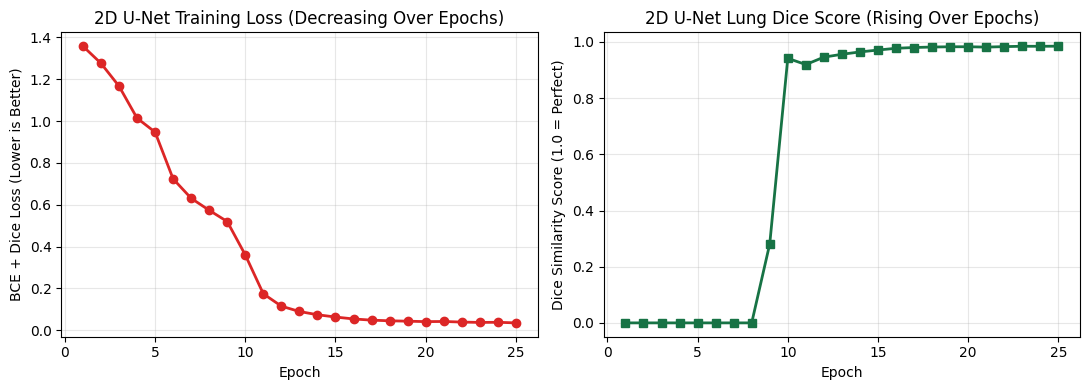

In [30]:
# Save the trained U-Net weights to your Google Drive models folder
model_save_path = os.path.join(MODEL_DIR, "simple_unet_xray.pth")
torch.save(unet_model.state_dict(), model_save_path)
print("Saved trained U-Net weights to Google Drive:", model_save_path)

# Plot the Decreasing Loss Curve and Rising Dice Score Curve side by side
epochs_range = range(1, len(loss_history) + 1)
plt.figure(figsize=(11, 4))

# Left Plot: Decreasing Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, loss_history, marker="o", color="#DC2626", linewidth=2)
plt.title("2D U-Net Training Loss (Decreasing Over Epochs)")
plt.xlabel("Epoch")
plt.ylabel("BCE + Dice Loss (Lower is Better)")
plt.grid(True, alpha=0.3)

# Right Plot: Rising Dice Similarity Score
plt.subplot(1, 2, 2)
plt.plot(epochs_range, dice_history, marker="s", color="#177345", linewidth=2)
plt.title("2D U-Net Lung Dice Score (Rising Over Epochs)")
plt.xlabel("Epoch")
plt.ylabel("Dice Similarity Score (1.0 = Perfect)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 5.1 and work toward Exercise 5.5.</font> <font color="#334155">Practice computing segmentation losses, inspecting the training history, and reloading saved weights from Google Drive.</font></p>

<p><font color="#7135B5"><b>Exercise 5.1 — Convert a Dice Score into a Dice Loss</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> If an AI model achieves a <code>dice_score = 0.85</code> on a lung scan, what is its <code>dice_loss</code> (using <code>1.0 - dice_score</code>)? Compute and print <code>round(dice_loss, 2)</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>0.15</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Set <code>dice_score = 0.85</code>, compute <code>dice_loss = 1.0 - dice_score</code>, and print <code>round(dice_loss, 2)</code>.</font></p>


In [31]:
# Exercise 5.1 — Convert a Dice Score into a Dice Loss
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 5.2 — Compare the First Epoch Loss vs. the Final Epoch Loss</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Using the <code>loss_history</code> list from Worked Example 1, print the starting loss at Epoch 1 (<code>round(loss_history[0], 3)</code>) on line 1, and the final loss at Epoch 25 (<code>round(loss_history[-1], 3)</code>) on line 2.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A high starting loss (~<code>1.1</code>) on line 1, and a low final loss (~<code>0.05</code>) on line 2.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>print(round(loss_history[0], 3))</code> and <code>print(round(loss_history[-1], 3))</code>.</font></p>


In [32]:
# Exercise 5.2 — Compare the First Epoch Loss vs. the Final Epoch Loss
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 5.3 — Compute <code>bce_dice_loss</code> on two identical masks vs. two opposite masks</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Using the provided 4D mask <code>true_m = Y_test[0:1]</code>, compute and print <code>round(bce_dice_loss(good_pred, true_m).item(), 3)</code> where <code>good_pred = true_m * 0.98 + 0.01</code> (almost identical!) on line 1, and <code>round(bce_dice_loss(bad_pred, true_m).item(), 3)</code> where <code>bad_pred = 1.0 - good_pred</code> (completely inverted!) on line 2.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">When the prediction matches the true lung mask, the combined loss is tiny (~<code>0.03</code>). When the prediction is backwards, the combined loss skyrockets above <code>5.0</code>!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> Around <code>0.033</code> on line 1, and around <code>5.545</code> on line 2.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Print <code>round(bce_dice_loss(good_pred, true_m).item(), 3)</code> and <code>round(bce_dice_loss(bad_pred, true_m).item(), 3)</code>.</font></p>


In [33]:
# Exercise 5.3 — Compute bce_dice_loss on two identical masks vs. two opposite masks
true_m = Y_test[0:1]
good_pred = true_m * 0.98 + 0.01
bad_pred = 1.0 - good_pred
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 5.4 — Verify that your saved U-Net model file exists in Google Drive and reload it</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Create a fresh <code>loaded_unet = SimpleUNet().to(device)</code> and load the saved weights from <code>model_save_path</code> using <code>loaded_unet.load_state_dict(torch.load(model_save_path, map_location=device))</code>. Print <code>os.path.exists(model_save_path)</code> to confirm.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> <code>True</code></p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Create <code>loaded_unet = SimpleUNet().to(device)</code>. &nbsp; 2. Call <code>loaded_unet.load_state_dict(torch.load(model_save_path, map_location=device))</code>. &nbsp; 3. Print <code>os.path.exists(model_save_path)</code>.</font></p>


In [34]:
# Exercise 5.4 — Verify that your saved U-Net model file exists in Google Drive and reload it
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 5.5 — Plot how the Training Error Rate (<code>1.0 - Dice</code>) decreases over epochs</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> Convert <code>dice_history</code> into a list of Dice Losses: <code>dice_loss_curve = [1.0 - d for d in dice_history]</code>, and plot it using <code>plt.plot(dice_loss_curve, marker="o")</code> with a title and axis labels.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A smooth downward-sloping line plot starting around <code>0.70</code> and dropping below <code>0.04</code>.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">1. Compute <code>dice_loss_curve = [1.0 - d for d in dice_history]</code>. &nbsp; 2. Call <code>plt.plot(dice_loss_curve, marker="o")</code>, add labels, and call <code>plt.show()</code>.</font></p>


In [35]:
# Exercise 5.5 — Plot how the Training Error Rate (1.0 - Dice) decreases over epochs
# Write your Python code below.


<hr>
<h2><font color="#1D4ED8"><b>6. AI Segmentation in Action: Side-by-Side Comparison on Unseen Test X-Rays</b></font></h2>

<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">Now comes the moment of truth! Remember in Lesson 3 when we locked away <b>4 unseen Test Patients (<code>X_test</code> and <code>Y_test</code>)</b> so our U-Net could never see them during training? Let's hand those unseen Chest X-Rays to our trained 2D U-Net and see how well the AI segments the lungs!</font></p>

<p><font color="#334155">To generate AI segmentations on test images, we follow three clean steps:</font></p>
<ol>
  <li><font color="#0E7490"><b>Switch to Evaluation Mode (<code>unet_model.eval()</code>):</b></font> <font color="#334155">Tells PyTorch we are testing the model, not training it.</font></li>
  <li><font color="#0E7490"><b>Predict Probabilities (<code>with torch.no_grad(): probs = unet_model(X_test)</code>):</b></font> <font color="#334155">For every pixel in the test X-ray, the U-Net outputs a probability between <code>0.0</code> and <code>1.0</code>.</font></li>
  <li><font color="#177345"><b>Threshold at 50% (<code>ai_masks = (probs &gt;= 0.5).float()</code>):</b></font> <font color="#334155">Any pixel with probability <code>&gt;= 0.5</code> becomes <code>1.0</code> (Lung), and everything else becomes <code>0.0</code> (Background)!</font></li>
</ol>

<h3><font color="#0E7490"><b>Worked example 1: Side-by-Side Display — Original X-Ray | Original Segmentation | AI Segmentation</b></font></h3>
<p><font color="#334155">Let's generate the AI segmentation for our first unseen test patient (`Test Patient 0`) and display the <b>3-panel comparison</b> side by side: <b>1. Original X-Ray Image</b>, <b>2. Original (Ground-Truth) Segmentation</b>, and <b>3. AI (2D U-Net) Segmentation</b>!</font></p>


Unseen Test Patient 0 — AI Dice Similarity Score: 0.9785 (97.9% overlap!)


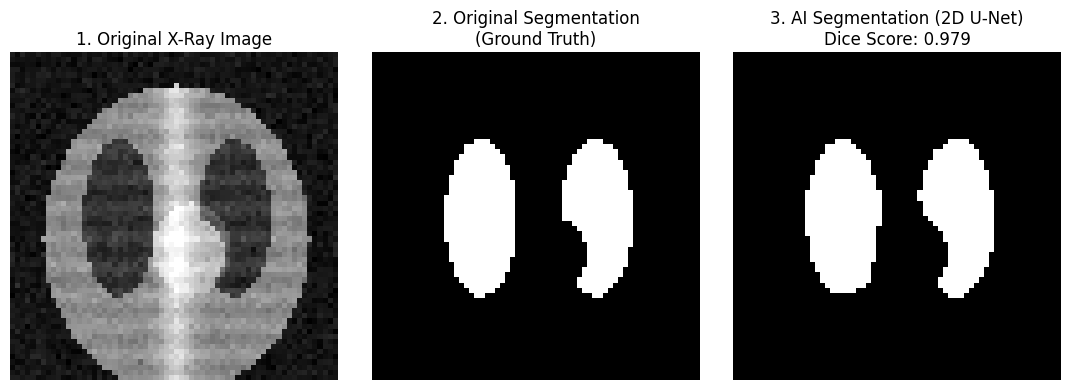

In [36]:
# Step 1: Switch U-Net to evaluation mode and predict on all 4 unseen Test X-rays
unet_model.eval()
with torch.no_grad():
    test_probs = unet_model(X_test.to(device)).cpu()
    ai_test_masks = (test_probs >= 0.5).float()

# Step 2: Inspect Test Patient 0 (Unseen during training!)
idx = 0
orig_img = X_test[idx].squeeze().numpy()
orig_seg = Y_test[idx].squeeze().numpy()
ai_seg   = ai_test_masks[idx].squeeze().numpy()

patient_dice = dice_score_fn(ai_test_masks[idx:idx+1], Y_test[idx:idx+1]).item()
print(f"Unseen Test Patient {idx} — AI Dice Similarity Score: {patient_dice:.4f} ({patient_dice*100:.1f}% overlap!)")

# Step 3: Plot Side-by-Side -> 1. Original Image | 2. Original Segmentation | 3. AI Segmentation
plt.figure(figsize=(11, 3.8))

plt.subplot(1, 3, 1)
plt.imshow(orig_img, cmap="gray")
plt.title("1. Original X-Ray Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(orig_seg, cmap="gray")
plt.title("2. Original Segmentation\n(Ground Truth)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(ai_seg, cmap="gray")
plt.title(f"3. AI Segmentation (2D U-Net)\nDice Score: {patient_dice:.3f}")
plt.axis("off")

plt.tight_layout()
plt.show()


<h3><font color="#0E7490"><b>Worked example 2: Multi-Patient Gallery — Side-by-Side Comparison Across All 4 Unseen Test Scans</b></font></h3>
<p><font color="#0E7490"><b>What this means (Intuitive Concept):</b></font> <font color="#334155">On a research poster, showing results across multiple unseen patients proves that your AI model works consistently even when lung sizes and shapes vary from person to person. Below, each row shows a different unseen test patient with four columns: <b>Original X-Ray</b>, <b>Original Segmentation</b>, <b>AI Segmentation</b>, and the <b>AI Overlay on the X-Ray</b>!</font></p>
<p><font color="#334155">Try it:</font> Run the next cell to generate the complete 4-patient evaluation gallery.</p>


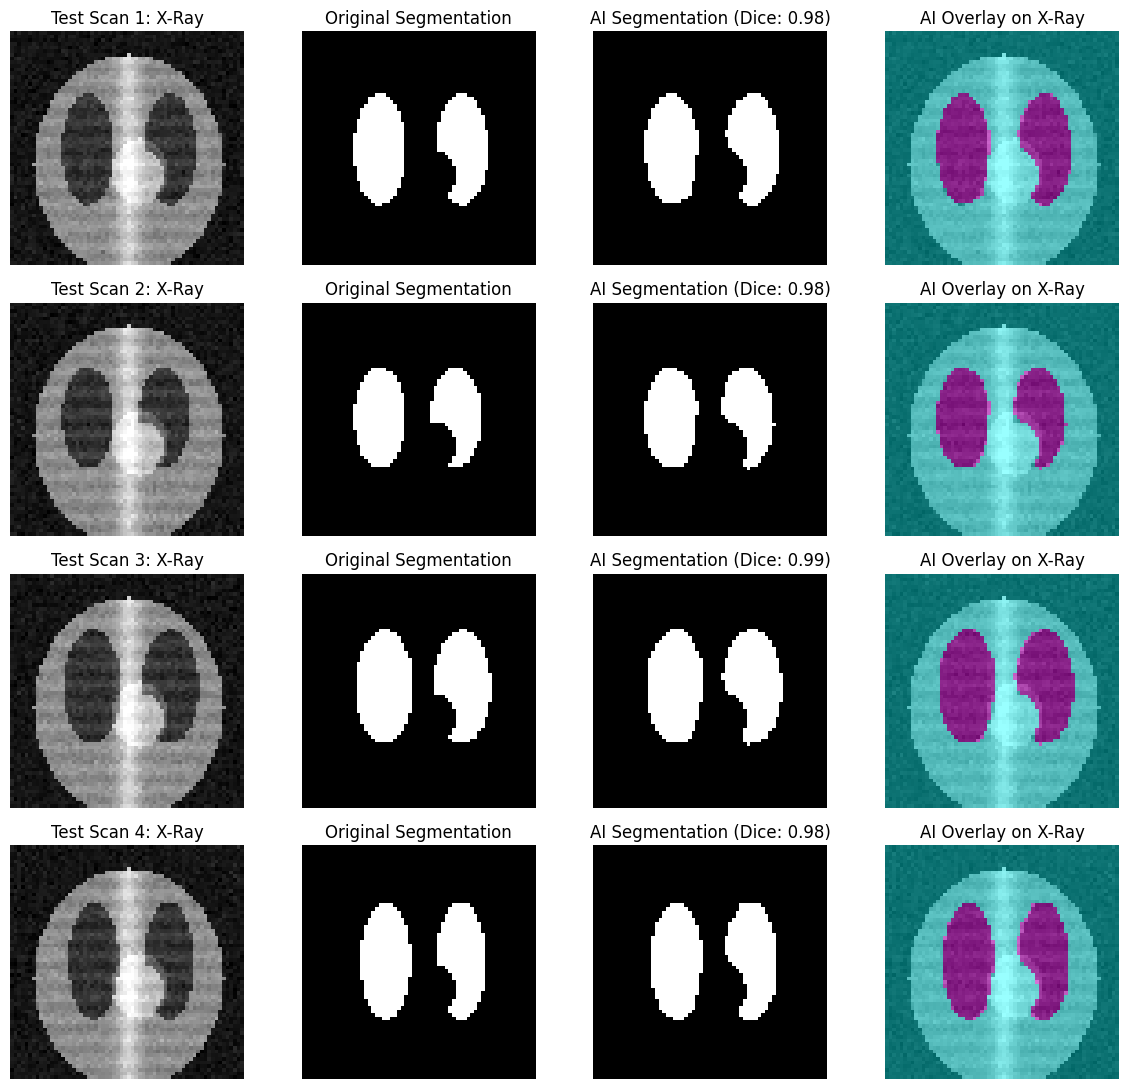

In [37]:
plt.figure(figsize=(12, 11))

for i in range(4):
    img_np  = X_test[i].squeeze().numpy()
    true_np = Y_test[i].squeeze().numpy()
    ai_np   = ai_test_masks[i].squeeze().numpy()
    score   = dice_score_fn(ai_test_masks[i:i+1], Y_test[i:i+1]).item()

    # Column 1: Original X-Ray Image
    plt.subplot(4, 4, i * 4 + 1)
    plt.imshow(img_np, cmap="gray")
    plt.title(f"Test Scan {i+1}: X-Ray")
    plt.axis("off")

    # Column 2: Original Ground-Truth Segmentation
    plt.subplot(4, 4, i * 4 + 2)
    plt.imshow(true_np, cmap="gray")
    plt.title("Original Segmentation")
    plt.axis("off")

    # Column 3: AI (U-Net) Segmentation
    plt.subplot(4, 4, i * 4 + 3)
    plt.imshow(ai_np, cmap="gray")
    plt.title(f"AI Segmentation (Dice: {score:.2f})")
    plt.axis("off")

    # Column 4: AI Segmentation Overlaid on X-Ray
    plt.subplot(4, 4, i * 4 + 4)
    plt.imshow(img_np, cmap="gray")
    plt.imshow(ai_np, cmap="cool", alpha=0.4)
    plt.title("AI Overlay on X-Ray")
    plt.axis("off")

plt.tight_layout()
plt.show()


<h3><font color="#7135B5"><b>Your turn: 5 exercises</b></font></h3>
<p><font color="#7135B5">Start with Exercise 6.1 and work toward Exercise 6.5.</font> <font color="#334155">Practice evaluating your trained 2D U-Net on unseen test patients and building side-by-side comparison figures.</font></p>

<p><font color="#7135B5"><b>Exercise 6.1 — Calculate the Average Dice Score across all 4 unseen Test Patients</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> Use <code>dice_score_fn(ai_test_masks, Y_test).item()</code> to compute the overall average Dice score across all 4 test scans, and print it rounded to 3 decimal places.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A high Dice score above <code>0.93</code>.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>avg_test_dice = dice_score_fn(ai_test_masks, Y_test).item()</code> and <code>print(round(avg_test_dice, 3))</code>.</font></p>


In [38]:
# Exercise 6.1 — Calculate the Average Dice Score across all 4 unseen Test Patients
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 6.2 — Compare True Lung Pixel Count vs. AI-Predicted Lung Pixel Count for Test Patient 1</b></font> &nbsp; <font color="#7135B5">(Easy)</font></p>
<p><font color="#334155"><b>Goal:</b> For Test Patient 1 (`index 1`), print the true number of lung pixels <code>int(Y_test[1].sum().item())</code> on line 1, and the AI-predicted number of lung pixels <code>int(ai_test_masks[1].sum().item())</code> on line 2.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> Two very close integer pixel counts (around <code>700</code> pixels).</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Write <code>print(int(Y_test[1].sum().item()))</code> and <code>print(int(ai_test_masks[1].sum().item()))</code>.</font></p>


In [39]:
# Exercise 6.2 — Compare True Lung Pixel Count vs. AI-Predicted Lung Pixel Count for Test Patient 1
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 6.3 — Display Side-by-Side: Original X-Ray, Original Segmentation, and AI Segmentation for Test Patient 2</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> Repeat the 3-panel side-by-side plot from Worked Example 1 for <b>Test Patient 2 (<code>idx = 2</code>)</b> showing <code>X_test[2]</code>, <code>Y_test[2]</code>, and <code>ai_test_masks[2]</code>.</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> A 3-panel row showing Test Patient 2's X-ray, Ground-Truth Segmentation, and AI Segmentation.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Use <code>plt.subplot(1, 3, 1)</code>, <code>(1, 3, 2)</code>, and <code>(1, 3, 3)</code> with <code>.squeeze()</code> on index <code>2</code>.</font></p>


In [40]:
# Exercise 6.3 — Display Side-by-Side: Original X-Ray, Original Seg, and AI Seg for Test Patient 2
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 6.4 — Visualize the Pixel Difference (Error Map) between Original Segmentation and AI Segmentation</b></font> &nbsp; <font color="#7135B5">(Medium)</font></p>
<p><font color="#334155"><b>Goal:</b> For Test Patient 0 (`idx = 0`), compute the absolute difference map <code>error_map = torch.abs(Y_test[0].squeeze() - ai_test_masks[0].squeeze())</code>, print how many pixels disagreed (<code>int(error_map.sum().item())</code>), and display <code>error_map</code> with <code>plt.imshow(error_map, cmap="gray")</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155">Everywhere the AI and the doctor agree is black (`0`), and only the thin 1-pixel border differences light up white (`1`)!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> The count of mismatched pixels followed by a mostly black image with a thin white rim along the lung edge.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Compute <code>error_map</code>, print <code>int(error_map.sum().item())</code>, and call <code>plt.imshow(error_map, cmap="gray")</code> and <code>plt.show()</code>.</font></p>


In [41]:
# Exercise 6.4 — Visualize the Pixel Difference (Error Map) between Original Seg and AI Seg
# Write your Python code below.


<p><font color="#7135B5"><b>Exercise 6.5 — Save a Side-by-Side AI Segmentation Result Figure directly to Google Drive!</b></font> &nbsp; <font color="#7135B5">(Challenge)</font></p>
<p><font color="#334155"><b>Goal:</b> Create a 1×3 side-by-side figure for Test Patient 3 (`idx = 3`), and before calling <code>plt.show()</code>, save the entire 3-panel comparison figure as a high-resolution PNG file in your Google Drive project folder using <code>plt.savefig(os.path.join(BASE_DIR, "ai_segmentation_result.png"))</code>. Print <code>os.path.exists(os.path.join(BASE_DIR, "ai_segmentation_result.png"))</code>.</font></p>
<p><font color="#0E7490"><b>Intuitive idea:</b></font> <font color="#334155"><code>plt.savefig(...)</code> exports your side-by-side comparison figure directly to Google Drive so you can drop it straight into your research poster or slides!</font></p>
<p><font color="#0E7490"><b>Expected output:</b></font> The 3-panel plot and <code>True</code> confirming the figure file was saved to Google Drive.</p>
<p><font color="#A34F00"><b>Step-by-step hint:</b></font> <font color="#A34F00">Draw the 3 subplots for <code>idx = 3</code>, call <code>plt.savefig(fig_path)</code>, call <code>plt.show()</code>, and print <code>os.path.exists(fig_path)</code>.</font></p>


In [42]:
# Exercise 6.5 — Save a Side-by-Side AI Segmentation Result Figure directly to Google Drive!
# Write your Python code below.


<hr>
<h1><font color="#177345"><b>Solutions — Check After You Try</b></font></h1>
<p><font color="#177345"><b>Complete solutions for Exercises 1.1 through 6.5 are provided below.</b></font> <font color="#334155">Run each cell to verify your output and review how each step works.</font></p>


=== LESSON 1 SOLUTIONS (Google Drive & Dataset Files) ===
1.1 Count of images in Drive -> 24
1.2 First 3 mask filenames -> ['xray_000.png', 'xray_001.png', 'xray_002.png']
1.3 Does xray_005.png exist? -> True
1.4 Do image and mask filenames match? -> True
1.5 2D Grayscale shape -> (64, 64)

=== LESSON 2 SOLUTIONS (Visualizing X-Rays & Masks) ===
2.1 Patient 3 lung pixel count -> 655
2.2 Percentage of image covered by lungs -> 13.9 %


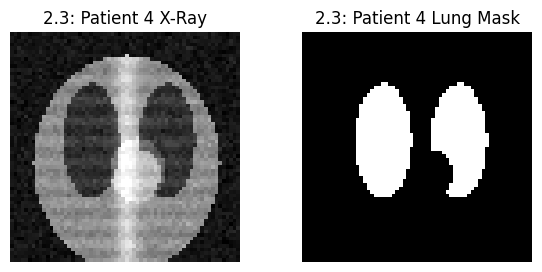

2.4 Mean brightness Inside Lungs: 0.21 | Outside Lungs: 0.36


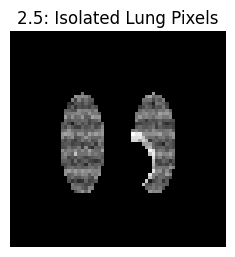


=== LESSON 3 SOLUTIONS (4D Tensors & DataLoaders) ===
3.1 4D shape -> torch.Size([1, 1, 64, 64])
3.2 Squeezed 2D shape -> torch.Size([64, 64])
3.3 Train patients: 20 | Test patients: 4
3.4 Number of test batches (batch_size=2) -> 2
3.5 Unique values in Y_train -> tensor([0., 1.])


In [43]:
print("=== LESSON 1 SOLUTIONS (Google Drive & Dataset Files) ===")

# Solution 1.1
files = os.listdir(IMG_DIR)
print("1.1 Count of images in Drive ->", len(files))

# Solution 1.2
mask_files = sorted(os.listdir(MASK_DIR))
print("1.2 First 3 mask filenames ->", mask_files[:3])

# Solution 1.3
path_005 = os.path.join(IMG_DIR, "xray_005.png")
print("1.3 Does xray_005.png exist? ->", os.path.exists(path_005))

# Solution 1.4
print("1.4 Do image and mask filenames match? ->", sorted(os.listdir(IMG_DIR)) == sorted(os.listdir(MASK_DIR)))

# Solution 1.5
raw_000 = plt.imread(os.path.join(IMG_DIR, "xray_000.png"))
gray_2d = raw_000[:, :, 0]
print("1.5 2D Grayscale shape ->", gray_2d.shape)

print("\n=== LESSON 2 SOLUTIONS (Visualizing X-Rays & Masks) ===")

# Solution 2.1
mask3 = (load_png_2d(os.path.join(MASK_DIR, "xray_003.png")) >= 0.5).astype(int)
print("2.1 Patient 3 lung pixel count ->", mask3.sum())

# Solution 2.2
pct_lung = float(sample_mask.mean() * 100)
print("2.2 Percentage of image covered by lungs ->", round(pct_lung, 1), "%")

# Solution 2.3
xray4 = load_png_2d(os.path.join(IMG_DIR, "xray_004.png"))
mask4 = (load_png_2d(os.path.join(MASK_DIR, "xray_004.png")) >= 0.5).astype(np.float32)
plt.figure(figsize=(6, 2.8))
plt.subplot(1, 2, 1)
plt.imshow(xray4, cmap="gray")
plt.title("2.3: Patient 4 X-Ray")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(mask4, cmap="gray")
plt.title("2.3: Patient 4 Lung Mask")
plt.axis("off")
plt.tight_layout()
plt.show()

# Solution 2.4
in_lung_mean  = round(float(sample_xray[sample_mask == 1].mean()), 2)
out_lung_mean = round(float(sample_xray[sample_mask == 0].mean()), 2)
print("2.4 Mean brightness Inside Lungs:", in_lung_mean, "| Outside Lungs:", out_lung_mean)

# Solution 2.5
isolated_lungs = sample_xray * sample_mask
plt.figure(figsize=(3, 2.8))
plt.imshow(isolated_lungs, cmap="gray")
plt.title("2.5: Isolated Lung Pixels")
plt.axis("off")
plt.show()

print("\n=== LESSON 3 SOLUTIONS (4D Tensors & DataLoaders) ===")

# Solution 3.1
single_img = torch.zeros((64, 64))
tensor_4d = single_img.unsqueeze(0).unsqueeze(0)
print("3.1 4D shape ->", tensor_4d.shape)

# Solution 3.2
tensor_2d = tensor_4d.squeeze()
print("3.2 Squeezed 2D shape ->", tensor_2d.shape)

# Solution 3.3
print("3.3 Train patients:", X_train.shape[0], "| Test patients:", X_test.shape[0])

# Solution 3.4
test_dataset = TensorDataset(X_test, Y_test)
test_loader = DataLoader(test_dataset, batch_size=2, shuffle=False)
print("3.4 Number of test batches (batch_size=2) ->", len(test_loader))

# Solution 3.5
print("3.5 Unique values in Y_train ->", torch.unique(Y_train))


=== LESSON 4 SOLUTIONS (2D U-Net Building Blocks) ===
4.1 After MaxPool2d(2) -> torch.Size([1, 16, 32, 32])
4.2 After Upsample(scale_factor=2) -> torch.Size([1, 32, 32, 32])
4.3 After Skip Connection torch.cat -> torch.Size([1, 48, 64, 64])
4.4 Single patient U-Net output shape -> torch.Size([1, 1, 64, 64])
4.5 Total learnable parameters in SimpleUNet -> 117985

=== LESSON 5 SOLUTIONS (Training & Loss Curves) ===
5.1 Dice Loss for 0.85 Dice Score -> 0.15
5.2 Epoch 1 Loss: 1.358 -> Final Epoch Loss: 0.036
5.3 Good Pred Loss: 0.041 | Bad Pred Loss: 5.602
5.4 Saved model exists & reloaded from Drive -> True


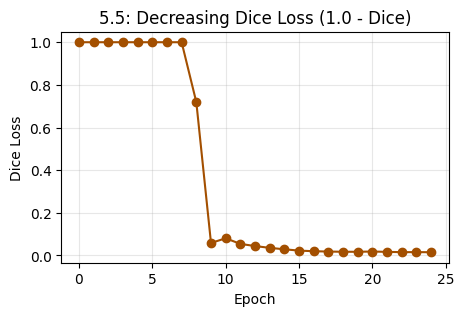


=== LESSON 6 SOLUTIONS (Side-by-Side AI Segmentation Evaluation) ===
6.1 Average Test Set Dice Score -> 0.98
6.2 Test Patient 1 True Lung Pixels: 554 | AI Lung Pixels: 571


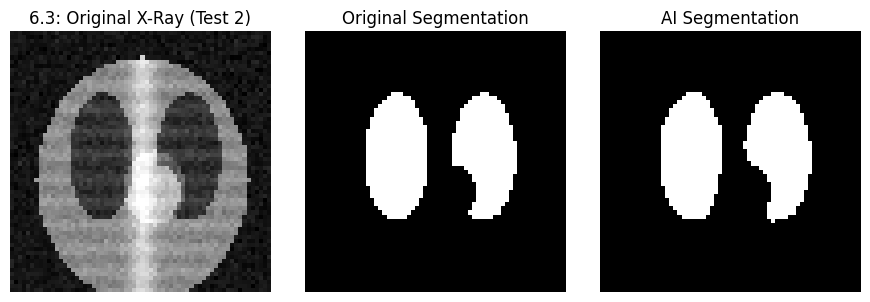

6.4 Mismatched pixels on Test Patient 0 -> 28


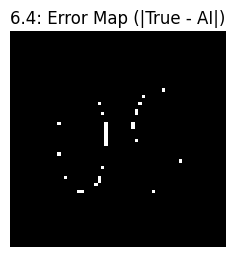

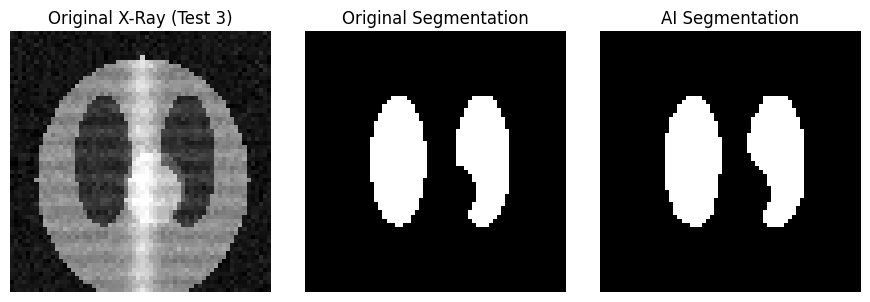

6.5 Saved comparison figure to Google Drive -> True


In [44]:
print("=== LESSON 4 SOLUTIONS (2D U-Net Building Blocks) ===")

# Solution 4.1
feat = torch.zeros((1, 16, 64, 64))
print("4.1 After MaxPool2d(2) ->", nn.MaxPool2d(2)(feat).shape)

# Solution 4.2
small_feat = torch.zeros((1, 32, 16, 16))
print("4.2 After Upsample(scale_factor=2) ->", nn.Upsample(scale_factor=2)(small_feat).shape)

# Solution 4.3
decoder_feat = torch.zeros((1, 32, 64, 64))
encoder_feat = torch.zeros((1, 16, 64, 64))
combined = torch.cat([decoder_feat, encoder_feat], dim=1)
print("4.3 After Skip Connection torch.cat ->", combined.shape)

# Solution 4.4
with torch.no_grad():
    pred_one = test_model(X_test[0:1])
print("4.4 Single patient U-Net output shape ->", pred_one.shape)

# Solution 4.5
total_params = sum(p.numel() for p in test_model.parameters())
print("4.5 Total learnable parameters in SimpleUNet ->", total_params)

print("\n=== LESSON 5 SOLUTIONS (Training & Loss Curves) ===")

# Solution 5.1
dice_score = 0.85
dice_loss = 1.0 - dice_score
print("5.1 Dice Loss for 0.85 Dice Score ->", round(dice_loss, 2))

# Solution 5.2
print("5.2 Epoch 1 Loss:", round(loss_history[0], 3), "-> Final Epoch Loss:", round(loss_history[-1], 3))

# Solution 5.3
true_m = Y_test[0:1]
good_pred = true_m * 0.98 + 0.01
bad_pred = 1.0 - good_pred
print("5.3 Good Pred Loss:", round(bce_dice_loss(good_pred, true_m).item(), 3),
      "| Bad Pred Loss:", round(bce_dice_loss(bad_pred, true_m).item(), 3))

# Solution 5.4
loaded_unet = SimpleUNet().to(device)
loaded_unet.load_state_dict(torch.load(model_save_path, map_location=device))
print("5.4 Saved model exists & reloaded from Drive ->", os.path.exists(model_save_path))

# Solution 5.5
dice_loss_curve = [1.0 - d for d in dice_history]
plt.figure(figsize=(5, 3))
plt.plot(dice_loss_curve, marker="o", color="#A34F00")
plt.title("5.5: Decreasing Dice Loss (1.0 - Dice)")
plt.xlabel("Epoch")
plt.ylabel("Dice Loss")
plt.grid(True, alpha=0.3)
plt.show()

print("\n=== LESSON 6 SOLUTIONS (Side-by-Side AI Segmentation Evaluation) ===")

# Solution 6.1
avg_test_dice = dice_score_fn(ai_test_masks, Y_test).item()
print("6.1 Average Test Set Dice Score ->", round(avg_test_dice, 3))

# Solution 6.2
print("6.2 Test Patient 1 True Lung Pixels:", int(Y_test[1].sum().item()),
      "| AI Lung Pixels:", int(ai_test_masks[1].sum().item()))

# Solution 6.3
plt.figure(figsize=(9, 3))
plt.subplot(1, 3, 1)
plt.imshow(X_test[2].squeeze(), cmap="gray")
plt.title("6.3: Original X-Ray (Test 2)")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(Y_test[2].squeeze(), cmap="gray")
plt.title("Original Segmentation")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(ai_test_masks[2].squeeze(), cmap="gray")
plt.title("AI Segmentation")
plt.axis("off")
plt.tight_layout()
plt.show()

# Solution 6.4
error_map = torch.abs(Y_test[0].squeeze() - ai_test_masks[0].squeeze())
print("6.4 Mismatched pixels on Test Patient 0 ->", int(error_map.sum().item()))
plt.figure(figsize=(3, 2.8))
plt.imshow(error_map, cmap="gray")
plt.title("6.4: Error Map (|True - AI|)")
plt.axis("off")
plt.show()

# Solution 6.5
fig_path = os.path.join(BASE_DIR, "ai_segmentation_result.png")
plt.figure(figsize=(9, 3))
plt.subplot(1, 3, 1)
plt.imshow(X_test[3].squeeze(), cmap="gray")
plt.title("Original X-Ray (Test 3)")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(Y_test[3].squeeze(), cmap="gray")
plt.title("Original Segmentation")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(ai_test_masks[3].squeeze(), cmap="gray")
plt.title("AI Segmentation")
plt.axis("off")
plt.tight_layout()
plt.savefig(fig_path, dpi=150)
plt.show()
print("6.5 Saved comparison figure to Google Drive ->", os.path.exists(fig_path))


<hr>
<h1><font color="#1D4ED8"><b>Quick Reference — 2D U-Net &amp; Google Drive Segmentation Cheat Sheet</b></font></h1>

<table style="width:100%;border-collapse:collapse;margin-top:8px;margin-bottom:12px;">
<tr style="background:#eaf3ff">
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Workflow Step</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>Python / PyTorch Command</b></font></th>
  <th style="padding:8px;text-align:left"><font color="#1D4ED8"><b>What It Does</b></font></th>
</tr>
<tr>
  <td style="padding:7px"><b>1. Mount Google Drive</b></td>
  <td style="padding:7px"><code>from google.colab import drive</code><br><code>drive.mount("/content/drive")</code></td>
  <td style="padding:7px">Links your personal Google Drive so datasets and trained models are saved permanently in <code>/content/drive/MyDrive/...</code>.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>2. Overlay Mask on X-Ray</b></td>
  <td style="padding:7px"><code>plt.imshow(xray, cmap="gray")</code><br><code>plt.imshow(mask, cmap="Greens", alpha=0.4)</code></td>
  <td style="padding:7px">Draws the grayscale X-ray first and lays a 40% transparent colored lung mask directly on top.</td>
</tr>
<tr>
  <td style="padding:7px"><b>3. 4D Tensor Shape</b></td>
  <td style="padding:7px"><code>(Batch, Channels, Height, Width)</code><br><code>img.unsqueeze(0)</code> &nbsp;|&nbsp; <code>img.squeeze()</code></td>
  <td style="padding:7px">PyTorch 2D models require 4D input tensors (e.g., <code>(4, 1, 64, 64)</code>). Use <code>.squeeze()</code> to return to 2D <code>(64, 64)</code> for plotting.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>4. 2D U-Net Architecture</b></td>
  <td style="padding:7px"><b>Encoder:</b> <code>nn.MaxPool2d(2)</code><br><b>Decoder:</b> <code>nn.Upsample(scale_factor=2)</code><br><b>Skip:</b> <code>torch.cat([up, enc], dim=1)</code></td>
  <td style="padding:7px">Zooms out to capture chest context, zooms back in to restore pixel resolution, and glues skip connections across to keep lung edges sharp.</td>
</tr>
<tr>
  <td style="padding:7px"><b>5. Segmentation Loss</b></td>
  <td style="padding:7px"><code>loss = bce_loss + (1.0 - dice_score)</code></td>
  <td style="padding:7px">Combines pixel-by-pixel Binary Cross-Entropy with whole-organ Dice overlap loss. Decreases toward <code>0.0</code> as the U-Net learns.</td>
</tr>
<tr style="background:#f8fafc">
  <td style="padding:7px"><b>6. Side-by-Side AI Inference</b></td>
  <td style="padding:7px"><code>unet_model.eval()</code><br><code>with torch.no_grad():</code><br>&nbsp;&nbsp;<code>ai_mask = (unet_model(x) &gt;= 0.5).float()</code></td>
  <td style="padding:7px">Generates AI segmentation masks on unseen test scans for side-by-side comparison against the original segmentation.</td>
</tr>
</table>